# Soil Object

The `Soil` object starts from a USDA soil texture layer stored as a raster. Each pixel in that raster represents a soil texture class, and those classes are commonly interpreted through the USDA soil texture triangle.

<p align="center">
  <img src="assets/usda-soil-texture-triangle.jpg" alt="USDA soil texture triangle" width="420">
</p>

The USDA texture triangle helps relate soil classes such as `clay`, `loam`, `silt loam`, or `sand` to their relative proportions of sand, silt, and clay. In this project, the raster does not store those percentages directly for each pixel. Instead, it stores a texture class identifier, and the code maps each identifier to hydrological parameters.

Soil source data can be retrieved from the FAO Harmonized World Soil Database v2.0:
https://www.fao.org/soils-portal/data-hub/soil-maps-and-databases/harmonized-world-soil-database-v20/en/

Before using the data in this workflow, the soil layers must be prepared as aligned rasters so that they match the model grid, extent, resolution, and coordinate reference system.

When `Soil.from_texture(...)` is called, the model converts the texture class raster into parameter rasters such as:

- `field_capacity`
- `wilting_point`
- `max_infiltration_rate`

The next cell reads the soil texture raster used by the main workflow and prints some basic information about it.

In [1]:
import numpy as np
import rasterio

static_folder = "/home/fremen/data/projects/DAO/00_static"
soil_texture_path = f"{static_folder}/soil_texture_aligned.tif"

with rasterio.open(soil_texture_path) as src:
    soil_texture = src.read(1)

print(soil_texture_path)
print(f"Raster shape: {soil_texture.shape}")
print(f"Raster dtype: {soil_texture.dtype}")
print(f"Unique texture IDs: {np.unique(soil_texture)[:20]}")

/home/fremen/data/projects/DAO/00_static/soil_texture_aligned.tif
Raster shape: (256, 285)
Raster dtype: float32
Unique texture IDs: [ 1.  2.  3.  4.  5.  7.  9. 11. 12. 13. nan]


## Example: build soil data from SoilGrids

The example below shows how to create a `Soil` object from the SoilGrids service using the working grid as the reference raster. It downloads or reuses the depth layers, aligns them to the reference grid, derives the USDA texture classes, and plots the resulting texture map.

If you already ran the cell once, it will reuse the cached SoilGrids rasters saved in the output folder.

        *** DOWNLOADING ISRIC SOILGRIDS DATA ***
clay
             *** All clay layers already downloaded, skipping WCS query ***
sand
             *** All sand layers already downloaded, skipping WCS query ***
silt
             *** All silt layers already downloaded, skipping WCS query ***
soc
             *** All soc layers already downloaded, skipping WCS query ***
Averaging soil layers and align to mask
 Skipping /home/fremen/data/projects/DAO/00_static/soilgrids_processed/soil_clay_averaged.tif, already exists.
 Skipping /home/fremen/data/projects/DAO/00_static/soilgrids_processed/soil_sand_averaged.tif, already exists.
 Skipping /home/fremen/data/projects/DAO/00_static/soilgrids_processed/soil_silt_averaged.tif, already exists.


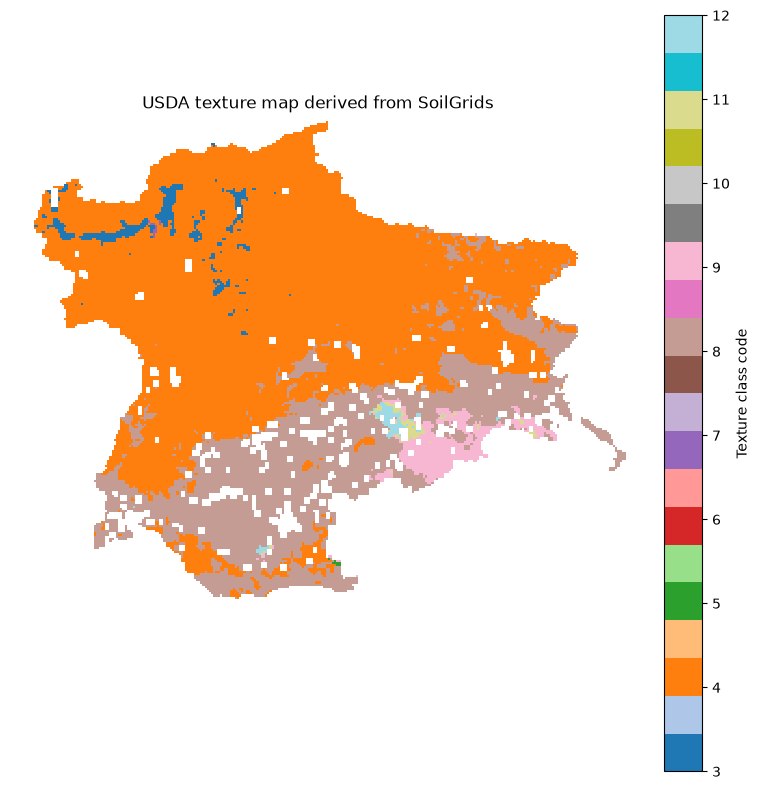

In [2]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import iwr

working_grid_path = f"{static_folder}/working_grid_3035_1km_precip_valid.tif"

soil = iwr.Soil.from_soilgrid(
    reference_path=working_grid_path,
    output_folder=static_folder,
)

soil.derive_usda_texture()

texture = np.ma.masked_equal(soil.texture_map, 0)

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(texture, cmap="tab20", interpolation="nearest")
ax.set_title("USDA texture map derived from SoilGrids")
fig.colorbar(im, ax=ax, label="Texture class code")
ax.axis("off")
fig.tight_layout()
display(fig)
plt.close(fig)

## Initialize soil moisture from field capacity

The next example sets the soil moisture state to `field_capacity` and visualizes three related rasters:

- `field_capacity`
- `wilting_point`
- `soil_moisture`

This helps verify that the soil object is initialized correctly before it is passed into the model.

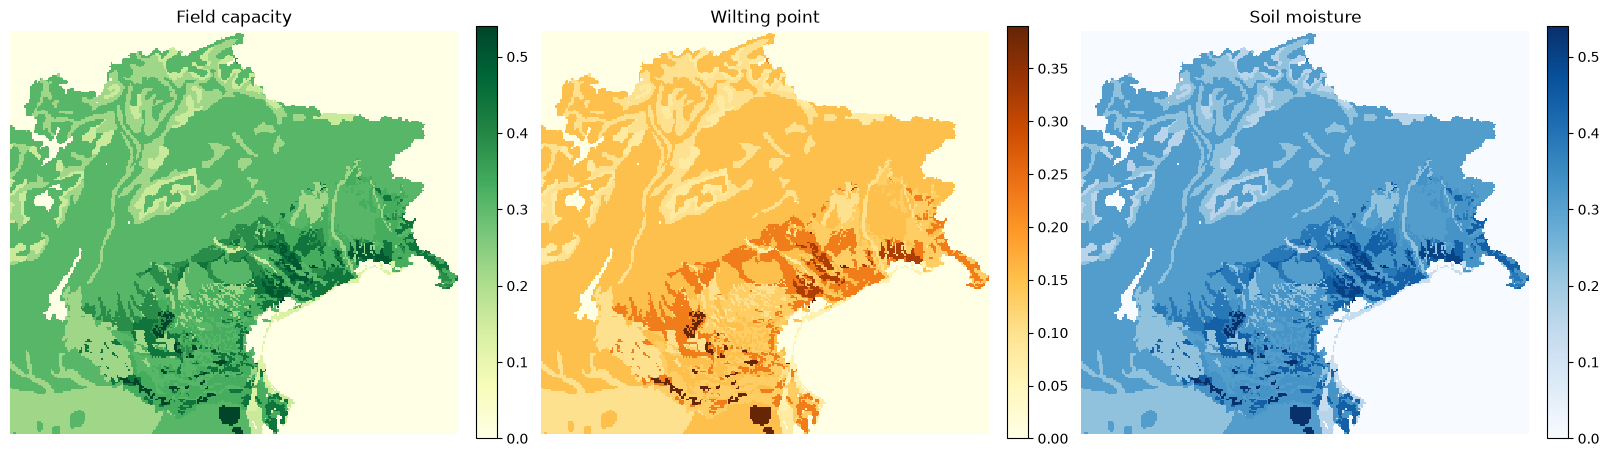

In [3]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import iwr

soil = iwr.Soil.from_texture(soil_texture)
soil.initialize_SM_from_string("field_capacity")

field_capacity = np.ma.masked_invalid(soil.field_capacity)
wilting_point = np.ma.masked_invalid(soil.wilting_point)
soil_moisture = np.ma.masked_invalid(soil.soil_moisture)

fig, axes = plt.subplots(1, 3, figsize=(16, 6), constrained_layout=True)

plots = [
    (field_capacity, "Field capacity", "YlGn"),
    (wilting_point, "Wilting point", "YlOrBr"),
    (soil_moisture, "Soil moisture", "Blues"),
]

for ax, (data, title, cmap) in zip(axes, plots):
    image = ax.imshow(data, cmap=cmap, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

plt.show()